# Tutorial 7: Aligning spatial transcriptomics, spatial epigenomics data and H&E image of mouse embryonic brain data from MISAR-seq

## Data Preparation

Please download the required data files from the provided link:
[Download here](https://pan.baidu.com/s/17K1cmxOPmhSvV6dG6gnafw?pwd=sjbx)

- `E11_0-S1-HE.jpg`
- `E11.0-S1-RNA.h5ad`
- `E11.0-S2-genescore.h5ad`

After downloading, place both files into the `datasets` folder located in the same directory as this notebook.

The folder structure should be organized as follows:

```
project_root/
│
├── datasets/
│   └── MISAR2/
│       ├── E11_0-S1-HE.jpg
│       ├── E11.0-S1-RNA.h5ad
│       └── E11.0-S2-genescore.h5ad
│
├── Tutorial7_Aligning_spatial_transcriptomics_spatial_epigenomics_data_and_H&E_image_of_mouse_embryonic_brain_data_from_MISAR-seq.ipynb
│
└── SpaMOMA/
```

## import packages

In [1]:
import scanpy as sc
from SpaMOMA.SpaMOMA import SpaMOMA

## Specify Slice Metadata

In [2]:
save_directory = "./SpaMOMA_output/MISAR2/"  
spamoma = SpaMOMA(save_dir=save_directory)
spamoma.add_slice(
    sample_id="S1-HE", 
    raw_data_path="./datasets/MISAR2/E11_0-S1-HE.jpg",  
    feature="img"  
)
spamoma.add_slice(
    sample_id="S1-RNA", 
    raw_data_path="./datasets/MISAR2/E11.0-S1-RNA.h5ad", 
    feature="rna"  
)
spamoma.add_slice(
    sample_id="S2-ATAC",  
    raw_data_path="./datasets/MISAR2/E11.0-S2-genescore.h5ad",  
    feature="gene_activity_score"  
)
spamoma.set_reference('S1-HE')
print(f"aligning {[sid for sid in spamoma.input_slice_dict.keys() if sid != spamoma.reference_sample_id]} to {spamoma.reference_sample_id}")

aligning ['S1-RNA', 'S2-ATAC'] to S1-HE


## Data Preprocessing

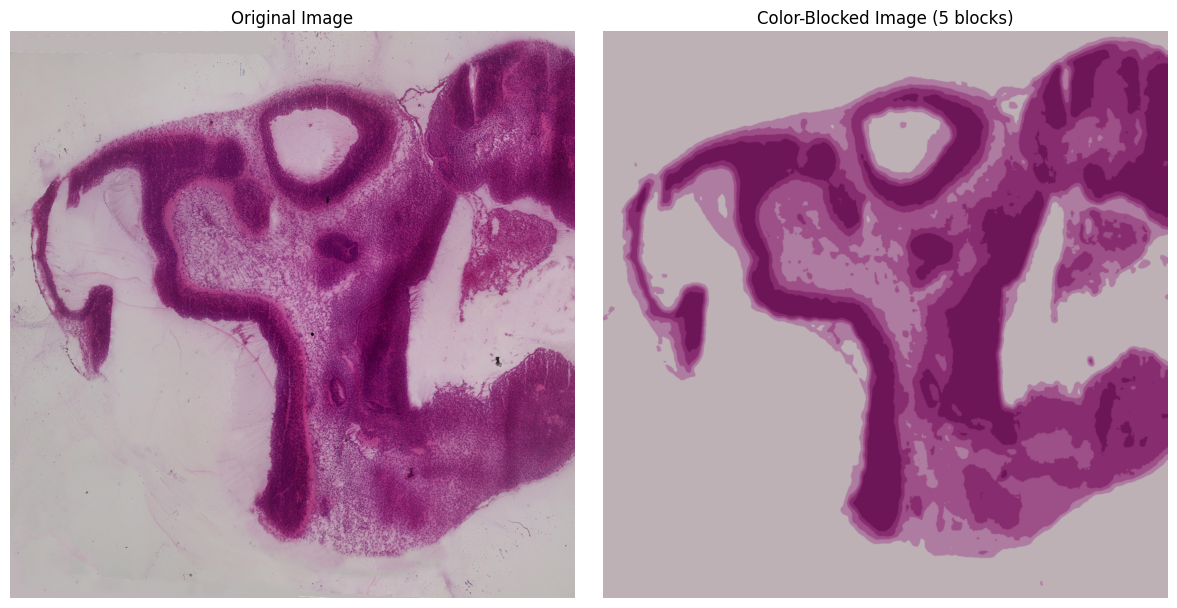

preprocessing rna features...


------Calculating spatial graph...
The graph contains 8841 edges, 1263 cells.
7.0000 neighbors per cell on average.


Size of Input:  (1263, 3000)


preprocessing gene_activity_score features...


------Calculating spatial graph...


The graph contains 9471 edges, 1353 cells.
7.0000 neighbors per cell on average.
Size of Input:  (1353, 3000)


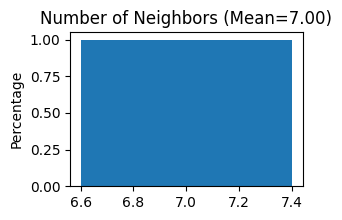

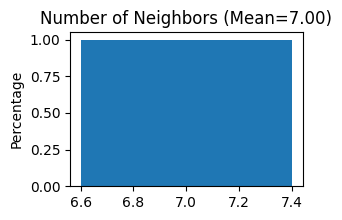

In [3]:
spamoma.preprocess_input_slices({
    'S1-HE':{
        'downsample':True
    }
})

## Generate Spatial Pattern Images

Color-quantized image saved to: ./SpaMOMA_output/MISAR2//S1-HE/RGB.png
generating spatial pattern image... gaussian_sigma:1.0, interpolation_method:linear, max_distance_ratio"0.9


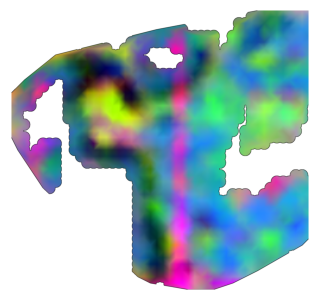

Img for S1-RNA is saved to ./SpaMOMA_output/MISAR2/S1-RNA/RGB.png
generating spatial pattern image... gaussian_sigma:1.0, interpolation_method:linear, max_distance_ratio"1.2


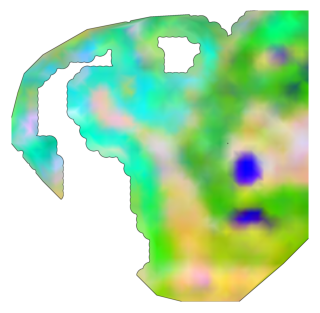

Img for S2-ATAC is saved to ./SpaMOMA_output/MISAR2/S2-ATAC/RGB.png


In [4]:
spamoma.generate_imgs({
    'S1-RNA':{
        'max_distance_ratio':0.9
    },
    'S2-ATAC':{
        'max_distance_ratio':1.2
    }
})

## Model Training

In [5]:
spamoma.train(coarse_epochs=100, fine_epochs=120)

{'status': 'completed',
 'run_dir': './SpaMOMA_output/MISAR2/runs/20261122-220236-08beb783'}

## Slice Alignment

In [6]:
spamoma.align_slices()

coarse checkpoint: ./SpaMOMA_output/MISAR2/runs/20261122-220236-08beb783/coarse_model/last.pth


fine checkpoint: ./SpaMOMA_output/MISAR2/runs/20261122-220236-08beb783/fine_model/last.pth


S1-HE image saved to: ./SpaMOMA_output/MISAR2//alignment_output/S1-HE.png


****************** aligning S1-RNA to S1-HE ..... ******************


aligned S1-RNA adata is saved to: ./SpaMOMA_output/MISAR2//alignment_output/S1-RNA.h5ad
fine alignment done!


****************** aligning S2-ATAC to S1-HE ..... ******************


aligned S2-ATAC adata is saved to: ./SpaMOMA_output/MISAR2//alignment_output/S2-ATAC.h5ad
fine alignment done!


## Visualize Alignment Results

Overlaying aligned slice for sample: S1-RNA


Overlaying aligned slice for sample: S2-ATAC


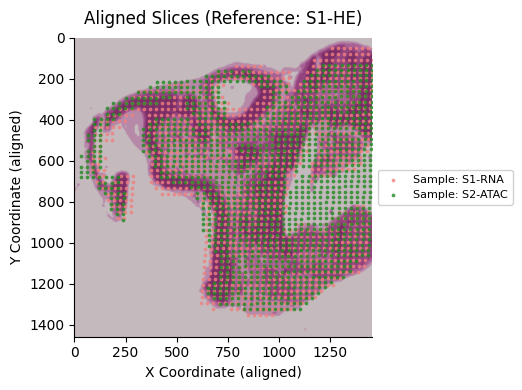

In [7]:
spamoma.visualize_aligned_slices(point_size=3,figsize=(5, 4))

## Enhancing low resolution spots to pixel-level resolution based on aligned coordinates

In [8]:
low_res_adata=spamoma.read_aligned_data('S1-RNA')

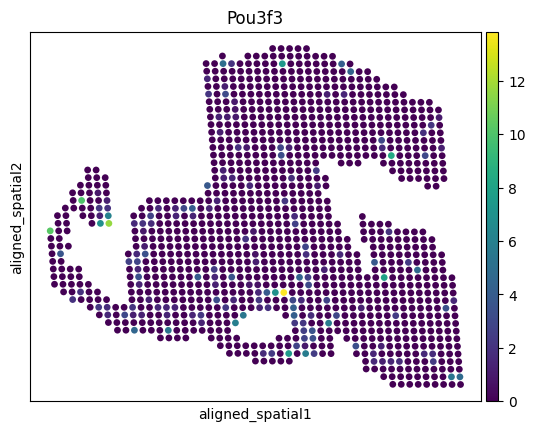

In [9]:
sc.pl.embedding(low_res_adata,color='Pou3f3',basis='aligned_spatial')

In [10]:
enhanced_adata=spamoma.SpaMOMA_enhance_resolution(adata=low_res_adata,img_path='./SpaMOMA_output/MISAR2/S1-HE/RGB.png')

  Running MAGIC on 1263 cells and 31433 genes.


  Running MAGIC with `solver='exact'` on 31433-dimensional data may take a long time. Consider denoising specific genes with `genes=<list-like>` or using `solver='approximate'`.


Calculated MAGIC in 6.94 seconds.


Number of valid sudo spots in tissue region: 11370


Number of valid known spots in tissue region: 1149


Final enhanced data dimensions: (11370, 31433)


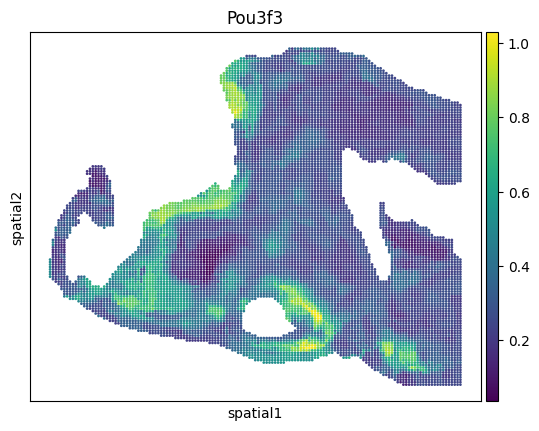

In [11]:
sc.pl.embedding(enhanced_adata,color='Pou3f3',s=15,basis='spatial')